In [1]:
import sys
import os

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

# **Load Data**

In [3]:
metadata_df = visualisation.load_df("../data/quinex/df_quinex_metadata.parquet")
quinex_df = visualisation.load_df("../data/quinex/df_quinex.parquet")

📂 Loaded DataFrame from '../data/quinex/df_quinex_metadata.parquet' with 14170 rows
📂 Loaded DataFrame from '../data/quinex/df_quinex.parquet' with 1347590 rows


# **Analysis Metadata**

keyword_group
Electrolyzer     4.233160
Fuel Cell        6.887284
Natural Gas     10.773280
Hydrogen        11.618792
Wind Turbine    15.040036
Battery         16.081528
PV              26.322862
Name: count, dtype: float64


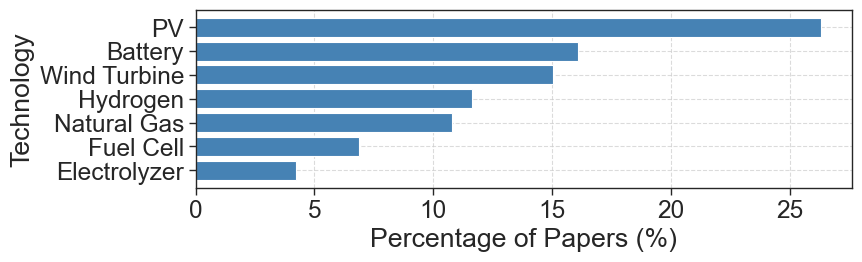

In [13]:
entity_keywords = {
    "Battery": ['battery', 'batteries', 'accumulator', "bess"],
    "Hydrogen": ['hydrogen', 'H2'],
    "PV": ['PV', 'photovoltaic', 'solar panel', 'solar cell'],
    "Wind Turbine": ["wind turbine", "wind farm", "offshore", "onshore", "wind energy", "nearshore"],
    "Natural Gas": ['natural gas', 'fossil gas', 'methane'],
    "Electrolyzer": ['electrolyzer', 'electrolyser'],
    "Fuel Cell": ['fuel cell', 'FC'],
}

fig, perc = metadata.keywords_distribution(quinex_df, entity_keywords, "entity", figsize=(9,3))
print(perc)
fig.savefig("../data/figures/technology_distribution.pdf")

keyword_group
performance    26.311664
efficiency     26.994793
emissions      34.643597
capacity       46.195196
cost           48.541352
lifetime       51.167479
Name: count, dtype: float64


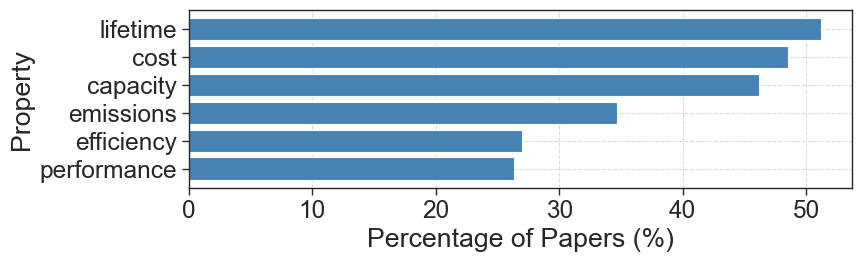

In [12]:
property_keywords = {
    "cost": ['cost', 'LCOE', 'LCOH', 'COE', 'Capex', 'Opex'],
    "lifetime": ["lifetime, durability", "duration", "life"],
    "capacity": ["capacity", "power output"],
    "efficiency": ["efficiency"],
    "emissions": ["CO2", "emission", "GHG", "carbon footprint"],
    "performance": ["performance", "yield", "output"],
}

fig, perc = metadata.keywords_distribution(quinex_df, property_keywords, "property", figsize=(9,3))
print(perc)
fig.savefig("../data/figures/property_distribution.pdf")

In [ ]:
fig = metadata.topics_distribution(metadata_df, "concepts", 12, use_percentage=True, show_other=True, figsize=(9,5))
fig.savefig("../data/figures/concept_distribution.pdf")

In [ ]:
fig, top_counts = metadata.journal_distribution(metadata_df, "publisher", 10, use_percentage=True, show_other=True, figsize=(9,5))
display(top_counts)
fig.savefig("../data/figures/publisher_distribution.pdf")

In [ ]:
fig, pivot = metadata.countries_share_year(metadata_df, 4, figsize = (10, 5), legend_position = (1, 1.03))
display(pivot)
fig.savefig("../data/figures/share_top_countries.pdf")

# **Analysis Results**

In [47]:
#technologies_df = visualisation.load_df("../data/visualisation_files/battery/df_battery_lifetime2.parquet")
technologies_df = visualisation.load_df("../data/visualisation_files/windturbine/df_windturbine.parquet")

📂 Loaded DataFrame from '../data/visualisation_files/windturbine/df_windturbine.parquet' with 4496 rows


In [54]:
technologies_df["entity"].value_counts().head(30)

entity
wind turbine                               1856
wind turbines                              1204
Wind turbine                                132
onshore wind turbines                        99
Wind turbines                                93
offshore wind turbines                       72
wind turbine system                          68
offshore wind turbine                        34
1.5 MW wind turbine                          33
wind turbine generator                       32
small wind turbines                          32
wind turbine farm                            29
wind turbine (WT)                            29
Wind Turbine                                 22
small wind turbine                           18
Onshore wind turbines                        17
the wind turbine                             14
wind turbines (WT)                           12
onshore wind turbine                         12
horizontal axis wind turbine                 12
wind turbine generators          

In [56]:
technologies_df[technologies_df["entity"] == "onshore wind turbines"]

,publication_year,paper_id,classification,entity,property,quantity_text,value_normalized,unit_normalized,quantity_normalized,quote,temporal_scope,spatial_scope,entity_mapping
38271,2025,10.1016/j.esr.2025.101681,"{'rational': 'arbitrary', 'system': 'model', 'type': 'observation'}",onshore wind turbines,average annual capacity factor,= 0.07,0.07,http://qudt.org/vocab/unit/UNITLESS,"{'quantities': [{'modifier': '=', 'unit': [{'exponent': None, 'unit_uri': 'http://qudt.org/vocab/unit/UNITLESS', 'year': None}], 'value': 0.07}], 'type': 'single_quantity'}","For all regions considered, the average annual capacity factor is found to be 0.22 for solar PV, 0.18 for thermal collectors, and 0.07 for onshore wind turbines.",2021,<NA>,Onshore Wind Turbine
61127,2025,10.1016/j.fuel.2025.134423,"{'rational': 'arbitrary', 'system': 'model', 'type': 'specification'}",onshore wind turbines,fixed operating and maintenance expenses,= 1.25 % and 1.67 %,1.46,http://qudt.org/vocab/unit/PERCENT,"{'quantities': [{'modifier': '=', 'unit': [{'exponent': 1.0, 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}], 'value': 1.25}, {'modifier': '=', 'unit': [{'exponent': 1.0, 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}], 'value': 1.67}], 'type': 'list'}","Additionally, 1.25 % and 1.67 % of these costs are allocated for fixed operating and maintenance expenses in 2030 and 2045, respectively. This study increases the capacity of onshore wind turbines to meet the power demand for green and blue ammonia production due to its economic advantages.",2030,<NA>,Onshore Wind Turbine
61148,2025,10.1016/j.fuel.2025.134423,"{'rational': None, 'system': 'model', 'type': 'observation'}",onshore wind turbines,required capacity,= 15.3 %,15.3,http://qudt.org/vocab/unit/PERCENT,"{'quantities': [{'modifier': '=', 'unit': [{'exponent': 1.0, 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}], 'value': 15.3}], 'type': 'single_quantity'}",This occurs because it efficiently decreases the required capacity of onshore wind turbines by 15.3 % for continuous ammonia production without necessitating exceedingly large hydrogen storage vessels.,<NA>,<NA>,Onshore Wind Turbine
61187,2025,10.1016/j.fuel.2025.134423,"{'rational': None, 'system': None, 'type': 'observation'}",onshore wind turbines,required capacity,= 15.3 %,15.3,http://qudt.org/vocab/unit/PERCENT,"{'quantities': [{'modifier': '=', 'unit': [{'exponent': 1.0, 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}], 'value': 15.3}], 'type': 'single_quantity'}","The study demonstrated that utilizing hydrogen storage to spread electrolyser demand over a week can decrease the required capacity for onshore wind turbines by 15.3 %, resulting in savings of €42 million in annual investment costs.",2030,<NA>,Onshore Wind Turbine
61195,2025,10.1016/j.fuel.2025.134423,"{'rational': None, 'system': None, 'type': 'observation'}",onshore wind turbines,required capacity,= 33.3 %,33.3,http://qudt.org/vocab/unit/PERCENT,"{'quantities': [{'modifier': '=', 'unit': [{'exponent': 1.0, 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}], 'value': 33.3}], 'type': 'single_quantity'}","It was also demonstrated that implementing 1-week flexible demand for electrolysers, facilitated by hydrogen storage, could reduce the required capacity of onshore wind turbines and the annual investment costs of the system by 33.3 % and 1.",2045,Denmark,Onshore Wind Turbine
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1120161,2017,10.1016/j.energy.2017.05.052,"{'rational': 'arbitrary', 'system': 'model', 'type': 'observation'}",onshore wind turbines,annual technical energy potential (TWh yr1),> 8760 h,8760.0,http://qudt.org/vocab/unit/HR,"{'quantities': [{'modifier': '>', 'unit': [{'exponent': 1.0, 'unit_uri': 'http://qudt.org/vocab/unit/HR', 'year': None}], 'value': 8760.0}], 'type': 'single_quantity'}",,<NA>,<NA>,Onshore Wind Turbine
1120165,2017,10.1016/j.energy.2017.05.052,"{'rational': 'ar

## **Visualise Results**

In [ ]:
vis_df = technologies_df
print(vis_df["unit_normalized"].value_counts())
vis_df = vis_df[vis_df["unit_normalized"]==("http://qudt.org/vocab/unit/YR")]
print(vis_df["entity_mapping"].value_counts())

### **Top Properties of the Data**

In [ ]:
fig = visualisation.plot_top_values(technologies_df, column="entity", top_n=20, ignore_empty=True, figsize=(6,6), title="Top 20 Entities")

### **Properties over Years**

In [ ]:
vis_df[vis_df["entity_mapping"] == "wind turbine"] 

In [ ]:
farbe_mapping = {
    'Hydrogen': '#000000',            # black
    'Blue Hydrogen': '#0072B2',       # blue
    'Grey Hydrogen': '#999999',       # gray
    'Yellow Hydrogen': '#E69F00',     # orange (statt gelb)
    'Green Hydrogen': '#009E73',      # green
    'Compressed Hydrogen': '#D55E00'  # reddish-orange
}

#vis_df = vis_df[vis_df["entity_mapping"].isin(["wind turbine", "pv", "electrolyzer",])]

fig = visualisation.plot_properties_over_time(vis_df, 'Lifetime [Years]', 'Lifetime of Technologies Over Time', 'Technology Type', plot_type="line", figsize=(12,6), central_tendency="moving average")
fig.show()

### **Spatial Scope on Map**

In [ ]:
vis_df1 = technologies_df
#print(vis_df1["unit_normalized"].value_counts())
vis_df1 = vis_df1[vis_df1["unit_normalized"]==("http://qudt.org/vocab/currency/USD / http://qudt.org/vocab/unit/KiloGM")]
print(vis_df1["entity_mapping"].value_counts())

vis_df2 = technologies_df
#print(vis_df2["unit_normalized"].value_counts())
vis_df2 = vis_df2[vis_df2["unit_normalized"]==("http://qudt.org/vocab/currency/USD / http://qudt.org/vocab/unit/KiloW-HR")]
print(vis_df2["entity_mapping"].value_counts())

In [ ]:
vis_df1 = vis_df1[vis_df1['spatial_scope'].notna()]
vis_df1['latitude'] = vis_df1['spatial_scope'].apply(
    lambda x: float(x['latitude']) if isinstance(x, dict) and 'latitude' in x else None
)

vis_df1['longitude'] = vis_df1['spatial_scope'].apply(
    lambda x: float(x['longitude']) if isinstance(x, dict) and 'longitude' in x else None
)
print(vis_df1["entity_mapping"].value_counts())

vis_df2 = vis_df2[vis_df2['spatial_scope'].notna()]
vis_df2['latitude'] = vis_df2['spatial_scope'].apply(
    lambda x: float(x['latitude']) if isinstance(x, dict) and 'latitude' in x else None
)

vis_df2['longitude'] = vis_df2['spatial_scope'].apply(
    lambda x: float(x['longitude']) if isinstance(x, dict) and 'longitude' in x else None
)
print(vis_df2["entity_mapping"].value_counts())

In [ ]:
display(vis_df2)

In [ ]:
farbe_mapping = {
    'Hydrogen': '#000000',            # Schwarz
    'Blue Hydrogen': '#0072B2',       # Blau
    'Grey Hydrogen': '#7F7F7F',       # Mittelgrau
    'Green Hydrogen': '#2ECC40',      # Helles Grasgrün
    'Compressed Hydrogen': '#FF851B', # Orange
    'Liquid Hydrogen': '#FF4136',     # Kräftiges Rot
    'Gaseous Hydrogen': '#B10DC9'     # Lila
}

#vis_df = vis_df[vis_df["entity_mapping"].isin(["Hydrogen", "Blue Hydrogen", "Green Hydrogen", "Grey Hydrogen"])]
#vis_df1 = vis_df1[vis_df1["entity_mapping"] == "Grey Hydrogen"]
vis_df2 = vis_df2[vis_df2["property_mapping"] != "Capital Cost"]

datasets = [
    {'df': vis_df1, 'marker': 'o', 'value_column': 'value_normalized', 'color_column': 'entity_mapping', 'size_legend_title': 'Levelized Cost [USD/kg]', 'legend_position': 0.13},
    {'df': vis_df2, 'marker': 's', 'value_column': 'value_normalized', 'color_column': 'entity_mapping', 'size_legend_title': 'Levelized Cost [USD/kWh]', 'legend_position': 0.32}
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    title="Geographical Distribution of Hydrogen Mentions in Scientific Literature",
    color_legend_title="Hydrogen Type",
    figsize=(14, 8),
    jitter_strength=1
)